In [ ]:
# Instalação com dependências flexibilizadas para evitar conflitos no Python 3.13
!pip install --only-binary :all: \
    google-ml-edu==0.1.3 \
    keras>=3.12.0 \
    matplotlib~=3.10.0 \
    numpy~=2.1.0 \
    pandas~=2.2.0 \
    tensorflow~=2.21.0

print('\n\nTodos os requisitos foram instalados com sucesso!')



Todos os requisitos foram instalados com sucesso!


In [ ]:
# data
import numpy as np
import pandas as pd

# machine learning
import keras
import ml_edu.experiment
import ml_edu.results

# data visualization
import plotly.express as px

In [ ]:
# Carregar o conjunto de dados usando a biblioteca google-ml-edu
import pandas as pd

try:
    # Carregando os dados de treino do Chicago Taxi usando a URL oficial e atualizada
    url = "https://developers.google.com/machine-learning/crash-course/california-housing-data-description?hl=pt-br" # backup
    # Caminho correto do Google ML Course para o Chicago Taxi Dataset:
    chicago_taxi_dataset = pd.read_csv("https://dl.google.com/mlcc/mledu-datasets/chicago_taxi_train.csv")
    print("Dataset dos Táxis de Chicago carregado com sucesso!")
except Exception as e:
    print("Erro ao carregar o dataset principal, tentando link alternativo:", e)
    try:
        chicago_taxi_dataset = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/chicago_taxi_train.csv")
        print("Dataset carregado via link alternativo!")
    except Exception as err:
        print("Erro em ambos os links:", err)

Dataset dos Táxis de Chicago carregado com sucesso!


In [ ]:
#@title Code - Read dataset

# Updates dataframe to use specific columns.
training_df = chicago_taxi_dataset.loc[:, ('TRIP_MILES', 'TRIP_SECONDS', 'FARE', 'COMPANY', 'PAYMENT_TYPE', 'TIP_RATE')]

print('Read dataset completed successfully.')
print('Total number of rows: {0}\n\n'.format(len(training_df.index)))
training_df.head(200)

Read dataset completed successfully.
Total number of rows: 31694




,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE
0,2.57,2341,31.99,Flash Cab,Mobile,6.3
1,1.18,1074,9.75,Flash Cab,Credit Card,27.9
2,1.29,1173,10.25,Sun Taxi,Cash,0.0
3,3.70,3360,23.75,Choice Taxi Association,Cash,0.0
4,1.15,1044,10.00,Flash Cab,Cash,0.0
...,...,...,...,...,...,...
195,1.13,821,9.00,Blue Ribbon Taxi Association,Mobile,22.9
196,0.57,414,6.00,Flash Cab,Cash,0.0
197,1.22,886,9.00,City Service,Cash,0.0
198,1.68,1219,9.00,Sun Taxi,Mobile,23.0


In [ ]:
print('Total number of rows: {0}\n\n'.format(len(training_df.index)))
training_df.describe(include='all')

Total number of rows: 31694




,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE
count,31694.000000,31694.000000,31694.000000,31694,31694,31694.000000
unique,NaN,NaN,NaN,31,7,NaN
top,NaN,NaN,NaN,Flash Cab,Credit Card,NaN
freq,NaN,NaN,NaN,7887,14142,NaN
mean,8.289463,1319.796397,23.905210,NaN,NaN,12.965785
std,7.265672,928.932873,16.970022,NaN,NaN,15.517765
min,0.500000,60.000000,3.250000,NaN,NaN,0.000000
25%,1.720000,548.000000,9.000000,NaN,NaN,0.000000
50%,5.920000,1081.000000,18.750000,NaN,NaN,12.200000
75%,14.500000,1888.000000,38.750000,NaN,NaN,20.800000


In [ ]:
training_df.corr(numeric_only=True)

,TRIP_MILES,TRIP_SECONDS,FARE,TIP_RATE
TRIP_MILES,1.000000,0.800855,0.975344,-0.049594
TRIP_SECONDS,0.800855,1.000000,0.830292,-0.084294
FARE,0.975344,0.830292,1.000000,-0.070979
TIP_RATE,-0.049594,-0.084294,-0.070979,1.000000


In [ ]:
#@title Double-click to view answers about the correlation matrix

# Which feature correlates most strongly to the label FARE?
# ---------------------------------------------------------
answer = '''
The feature with the strongest correlation to the FARE is TRIP_MILES.
As you might expect, TRIP_MILES looks like a good feature to start with to train
the model. Also, notice that the feature TRIP_SECONDS has a strong correlation
with fare too.
'''
print(answer)


# Which feature correlates least strongly to the label FARE?
# -----------------------------------------------------------
answer = '''The feature with the weakest correlation to the FARE is TIP_RATE.'''
print(answer)


The feature with the strongest correlation to the FARE is TRIP_MILES.
As you might expect, TRIP_MILES looks like a good feature to start with to train
the model. Also, notice that the feature TRIP_SECONDS has a strong correlation
with fare too.

The feature with the weakest correlation to the FARE is TIP_RATE.


In [ ]:
px.scatter_matrix(
    training_df,
    dimensions=["FARE", "TRIP_MILES", "TRIP_SECONDS"]
)

In [ ]:
def create_model(
    settings: ml_edu.experiment.ExperimentSettings,
    metrics: list[keras.metrics.Metric],
) -> keras.Model:
    """Create and compile a simple linear regression model."""

    inputs = {
        name: keras.Input(shape=(1,), name=name)
        for name in settings.input_features
    }

    concatenated_inputs = keras.layers.Concatenate()(list(inputs.values()))
    outputs = keras.layers.Dense(units=1)(concatenated_inputs)

    model = keras.Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer=keras.optimizers.RMSprop(
            learning_rate=settings.learning_rate
        ),
        loss="mean_squared_error",
        metrics=metrics
    )

    return model


def train_model(
    experiment_name: str,
    model: keras.Model,
    dataset: pd.DataFrame,
    label_name: str,
    settings: ml_edu.experiment.ExperimentSettings,
) -> ml_edu.experiment.Experiment:
    """Train the model by feeding it data."""

    features = {
        name: dataset[name].values
        for name in settings.input_features
    }

    label = dataset[label_name].values

    history = model.fit(
        x=features,
        y=label,
        batch_size=settings.batch_size,
        epochs=settings.number_epochs
    )

    return ml_edu.experiment.Experiment(
        name=experiment_name,
        settings=settings,
        model=model,
        epochs=history.epoch,
        metrics_history=pd.DataFrame(history.history),
    )


print("SUCCESS: defining linear regression functions complete.")

SUCCESS: defining linear regression functions complete.


Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 1054.8157 - rmse: 32.4779
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 641.1783 - rmse: 25.3215
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 330.1620 - rmse: 18.1704
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 126.7699 - rmse: 11.2592
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 29.7833 - rmse: 5.4574
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 15.2316 - rmse: 3.9028
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.6721 - rmse: 3.8304
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.3427 - rmse: 3.7872
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.1659 - rmse: 3.7638
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.0923 - rmse: 3.7540
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.0555 - rmse: 3.7491
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.0419 - rmse:

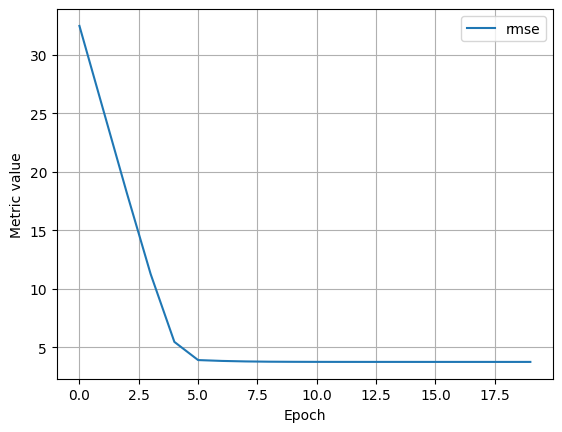

In [ ]:
settings_1 = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=20,
    batch_size=50,
    input_features=['TRIP_MILES']
)

metrics = [
    keras.metrics.RootMeanSquaredError(name='rmse')
]

model_1 = create_model(settings_1, metrics)

experiment_1 = train_model(
    'one_feature',
    model_1,
    training_df,
    'FARE',
    settings_1
)

ml_edu.results.plot_experiment_metrics(experiment_1, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_1, training_df, 'FARE')

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 73.0824 - rmse: 8.5488 
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 22.6956 - rmse: 4.7640
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 19.3584 - rmse: 4.3998
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 17.7494 - rmse: 4.2130
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 16.4570 - rmse: 4.0567
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 15.4874 - rmse: 3.9354
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 14.8243 - rmse: 3.8502
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.4228 - rmse: 3.7977
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.2109 - rmse: 3.7697
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.1084 - rmse: 3.7561
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.0643 - rmse: 3.7502
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.0441 - rmse: 3.7476


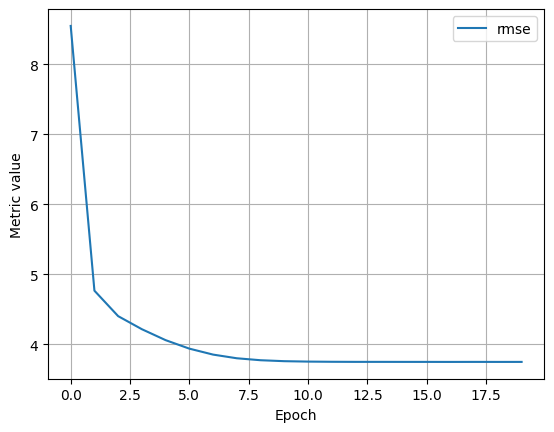

In [ ]:
settings_1 = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=20,
    batch_size=50,
    input_features=['TRIP_MILES']
)

metrics = [
    keras.metrics.RootMeanSquaredError(name='rmse')
]

model_1 = create_model(settings_1, metrics)

experiment_1 = train_model(
    'one_feature',
    model_1,
    training_df,
    'FARE',
    settings_1
)

ml_edu.results.plot_experiment_metrics(experiment_1, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_1, training_df, 'FARE')

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 49.3113 - rmse: 7.0222
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 48.3244 - rmse: 6.9516
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 47.4065 - rmse: 6.8852
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 48.0381 - rmse: 6.9309
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 47.1517 - rmse: 6.8667
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 47.9003 - rmse: 6.9210
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 48.3145 - rmse: 6.9509
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 47.7582 - rmse: 6.9107
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 47.7242 - rmse: 6.9083
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 47.3685 - rmse: 6.8825
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 47.6015 - rmse: 6.8994
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 47.3680 - rmse: 6.8824
E

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


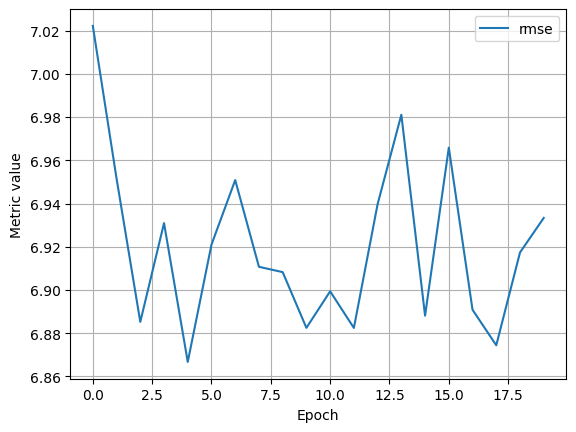

In [ ]:
settings_2 = ml_edu.experiment.ExperimentSettings(
    learning_rate=1.0,
    number_epochs=20,
    batch_size=50,
    input_features=['TRIP_MILES']
)

metrics = [
    keras.metrics.RootMeanSquaredError(name='rmse')
]

model_2 = create_model(settings_2, metrics)

experiment_2 = train_model(
    'high_learning_rate',
    model_2,
    training_df,
    'FARE',
    settings_2
)

ml_edu.results.plot_experiment_metrics(experiment_2, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_2, training_df, 'FARE')

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1232.5610 - rmse: 35.1078
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1181.9327 - rmse: 34.3792
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1132.6029 - rmse: 33.6542
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1083.9644 - rmse: 32.9236
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1036.7960 - rmse: 32.1993
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 990.3714 - rmse: 31.4702
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 945.2015 - rmse: 30.7441
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 900.7796 - rmse: 30.0130
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 858.0036 - rmse: 29.2917
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 816.0545 - rmse: 28.5667
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 775.1240 - rmse: 27.8410
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - los

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


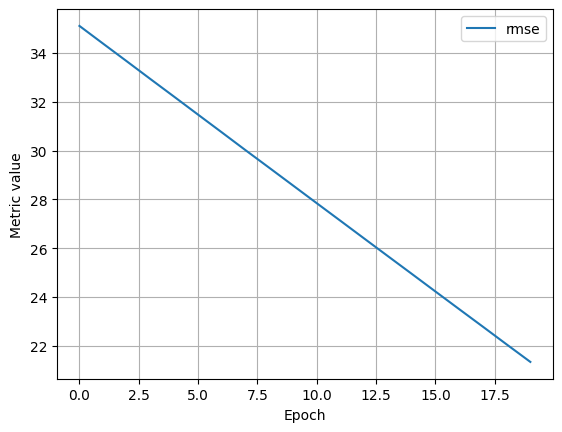

In [ ]:
settings_3 = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.0001,
    number_epochs=20,
    batch_size=50,
    input_features=['TRIP_MILES']
)

metrics = [
    keras.metrics.RootMeanSquaredError(name='rmse')
]

model_3 = create_model(settings_3, metrics)

experiment_3 = train_model(
    'low_learning_rate',
    model_3,
    training_df,
    'FARE',
    settings_3
)

ml_edu.results.plot_experiment_metrics(experiment_3, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_3, training_df, 'FARE')

Epoch 1/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1325.1084 - rmse: 36.4020
Epoch 2/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1270.3165 - rmse: 35.6415
Epoch 3/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1217.8562 - rmse: 34.8978
Epoch 4/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1166.3243 - rmse: 34.1515
Epoch 5/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1115.9174 - rmse: 33.4053
Epoch 6/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1066.6982 - rmse: 32.6603
Epoch 7/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1018.7991 - rmse: 31.9186
Epoch 8/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 971.6833 - rmse: 31.1718
Epoch 9/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 925.6402 - rmse: 30.4243
Epoch 10/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 881.0388 - rmse: 29.6823
Epoch 11/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 837.5219 - rmse: 28.9400
Epoch 12/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 794.8295 - rmse: 28

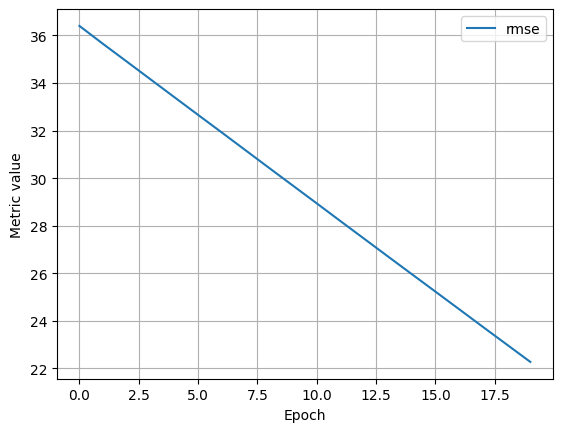

In [ ]:
settings_4 = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=20,
    batch_size=500,
    input_features=['TRIP_MILES']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_4 = create_model(settings_4, metrics)

experiment_4 = train_model(
    'large_batch_size',
    model_4,
    training_df,
    'FARE',
    settings_4
)

ml_edu.results.plot_experiment_metrics(experiment_4, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_4, training_df, 'FARE')

In [ ]:
training_df['TRIP_MINUTES'] = training_df['TRIP_SECONDS'] / 60

print("TRIP_MINUTES created successfully.")
training_df[['TRIP_SECONDS', 'TRIP_MINUTES']].head()

TRIP_MINUTES created successfully.


,TRIP_SECONDS,TRIP_MINUTES
0,2341,39.016667
1,1074,17.900000
2,1173,19.550000
3,3360,56.000000
4,1044,17.400000


Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1344.0133 - rmse: 36.6608
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 214.8620 - rmse: 14.6582
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.1017 - rmse: 3.7552
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 13.2521 - rmse: 3.6403
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 12.7503 - rmse: 3.5708
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.4446 - rmse: 3.5277
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.2652 - rmse: 3.5022
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.1717 - rmse: 3.4888
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.1336 - rmse: 3.4833
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.1146 - rmse: 3.4806
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.1024 - rmse: 3.4789
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.1040 - rmse: 3.4

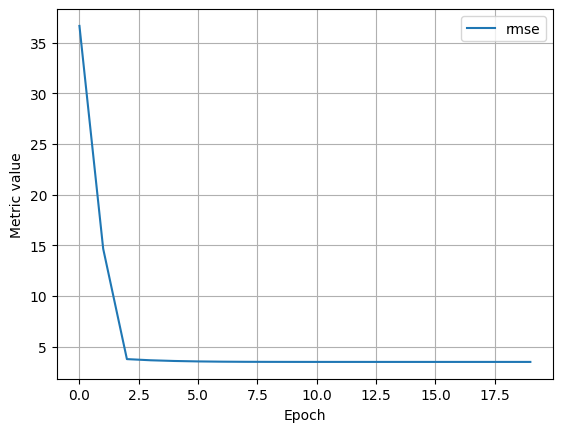

In [ ]:
settings_two = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=20,
    batch_size=50,
    input_features=['TRIP_MILES', 'TRIP_MINUTES']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_two = create_model(settings_two, metrics)

experiment_two = train_model(
    'two_features',
    model_two,
    training_df,
    'FARE',
    settings_two
)

ml_edu.results.plot_experiment_metrics(experiment_two, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_two, training_df, 'FARE')

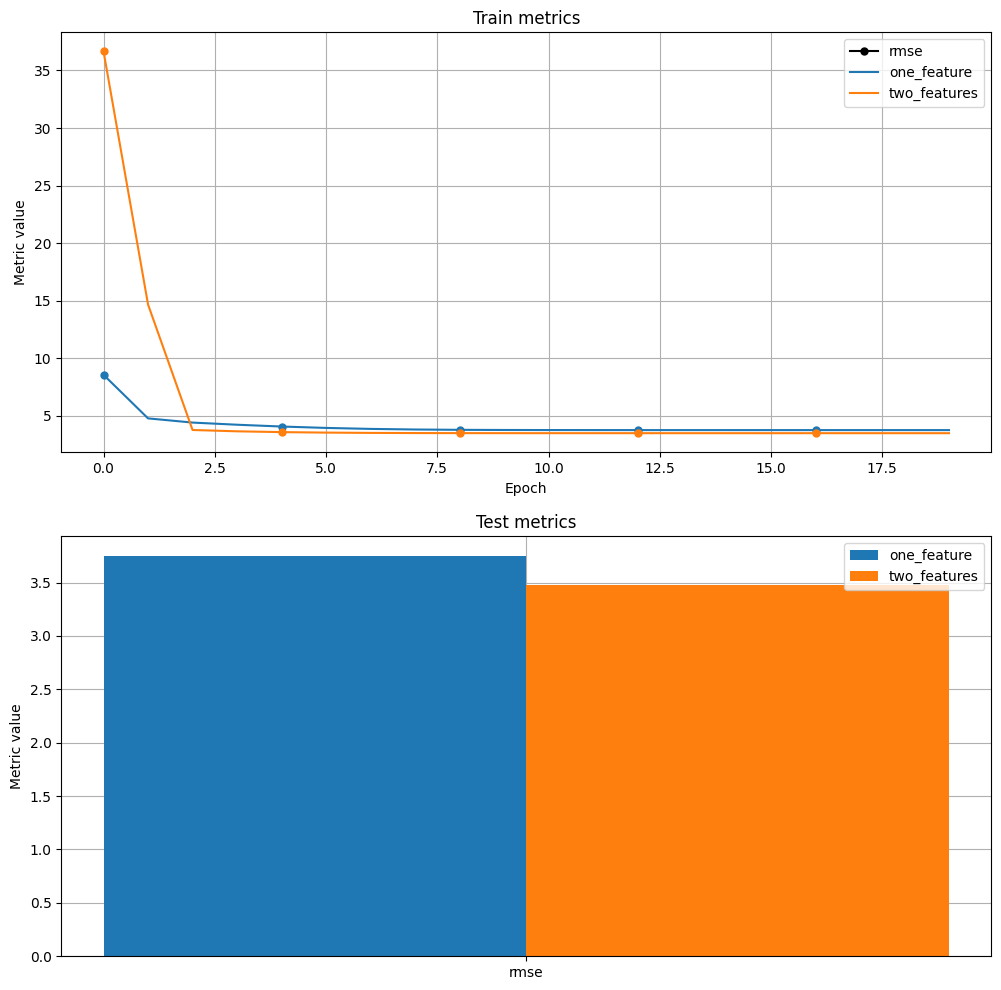

In [ ]:
ml_edu.results.compare_experiment(
    [experiment_1, experiment_two],
    ['rmse'],
    training_df,
    training_df['FARE'].values
)

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1383513.7500 - rmse: 1176.2286
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 89420.1953 - rmse: 299.0321 
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 275.8045 - rmse: 16.6074
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 209.1904 - rmse: 14.4634
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 153.7968 - rmse: 12.4015
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 106.4218 - rmse: 10.3161
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 69.8092 - rmse: 8.3552
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 43.4104 - rmse: 6.5887
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 26.7479 - rmse: 5.1718
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 18.1563 - rmse: 4.2610
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.9009 - rmse: 3.8602
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 13

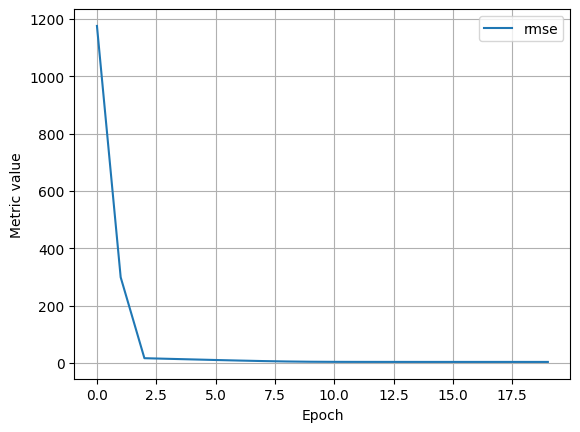

In [ ]:
settings_seconds = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=20,
    batch_size=50,
    input_features=['TRIP_MILES', 'TRIP_SECONDS']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_seconds = create_model(settings_seconds, metrics)

experiment_seconds = train_model(
    'two_features_seconds',
    model_seconds,
    training_df,
    'FARE',
    settings_seconds
)

ml_edu.results.plot_experiment_metrics(experiment_seconds, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_seconds, training_df, 'FARE')

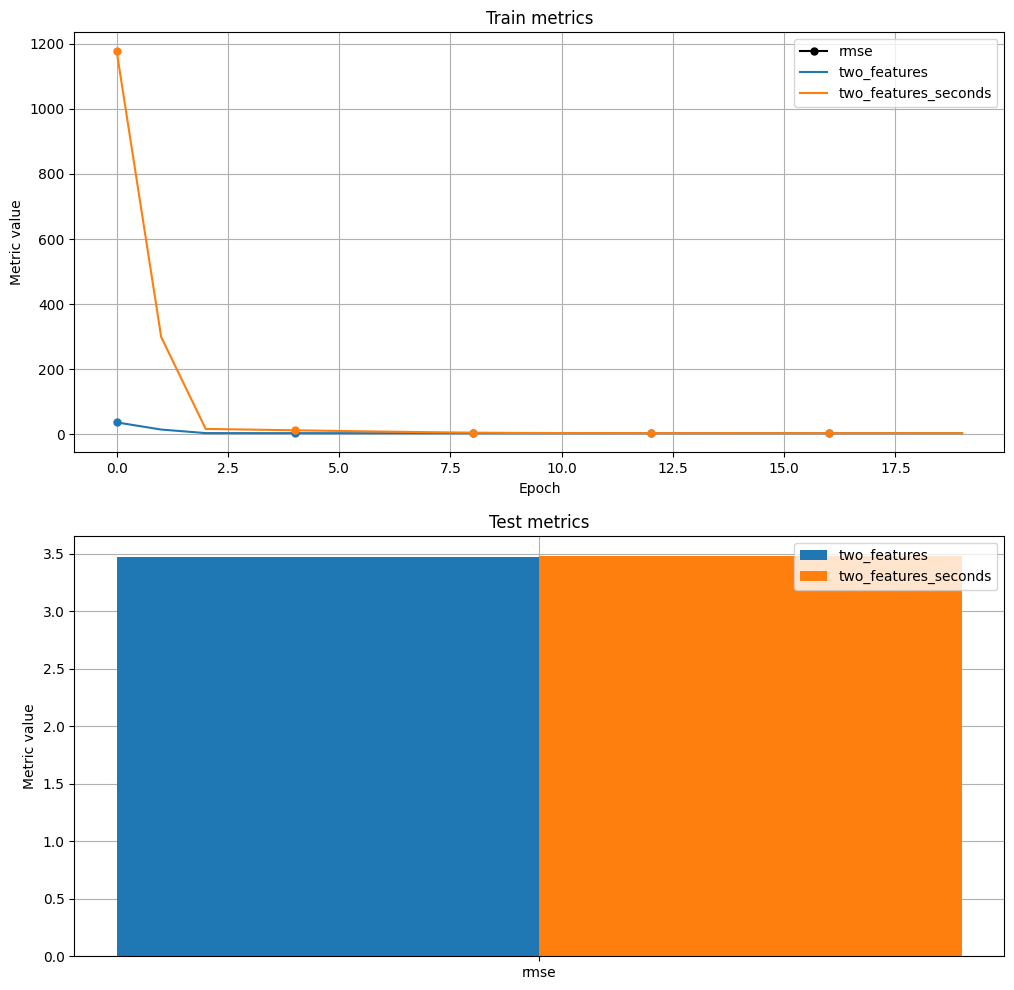

In [ ]:
ml_edu.results.compare_experiment(
    [experiment_two, experiment_seconds],
    ['rmse'],
    training_df,
    training_df['FARE'].values
)

In [ ]:
#@title Code - Define functions to make predictions
def format_currency(x):
  return "${:.2f}".format(x)

def build_batch(df, batch_size):
  batch = df.sample(n=batch_size).copy()
  batch.set_index(np.arange(batch_size), inplace=True)
  return batch

def predict_fare(model, df, features, label, batch_size=50):
  batch = build_batch(df, batch_size)
  predicted_values = model.predict_on_batch(x={name: batch[name].values for name in features})

  data = {"PREDICTED_FARE": [], "OBSERVED_FARE": [], "L1_LOSS": [],
          features[0]: [], features[1]: []}
  for i in range(batch_size):
    predicted = predicted_values[i][0]
    observed = batch.at[i, label]
    data["PREDICTED_FARE"].append(format_currency(predicted))
    data["OBSERVED_FARE"].append(format_currency(observed))
    data["L1_LOSS"].append(format_currency(abs(observed - predicted)))
    data[features[0]].append(batch.at[i, features[0]])
    data[features[1]].append("{:.2f}".format(batch.at[i, features[1]]))

  output_df = pd.DataFrame(data)
  return output_df

def show_predictions(output):
  header = "-" * 80
  banner = header + "\n" + "|" + "PREDICTIONS".center(78) + "|" + "\n" + header
  print(banner)
  print(output)
  return

In [ ]:
output = predict_fare(
    experiment_two.model,
    training_df,
    experiment_two.settings.input_features,
    'FARE'
)

show_predictions(output)

--------------------------------------------------------------------------------
|                                 PREDICTIONS                                  |
--------------------------------------------------------------------------------
   PREDICTED_FARE OBSERVED_FARE L1_LOSS  TRIP_MILES TRIP_MINUTES
0          $26.63        $26.25   $0.38        9.80        20.00
1          $34.44        $34.00   $0.44       13.51        21.93
2           $8.67         $8.00   $0.67        1.60        11.00
3          $37.13        $38.00   $0.87       13.20        45.00
4          $14.82        $14.25   $0.57        4.39        14.33
5          $13.43        $12.75   $0.68        4.23         6.97
6          $45.36        $44.75   $0.61       18.00        34.37
7           $7.22         $7.00   $0.22        1.10         8.00
8           $6.85         $6.25   $0.60        0.95         7.53
9          $24.71        $25.75   $1.04        8.68        22.47
10         $42.82        $43.75   $0.93   